<a href="https://colab.research.google.com/github/liwiaflorkiwicz/psychedelics_model/blob/datasetv0/thesis_dataset_v0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Draft analysis of PsiConnect Dataset (OpenNeuro: ds006110)**
Version 0 for dataset visualization

In [ ]:
# imports
!pip install -q pandas awscli matplotlib seaborn

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.


In [ ]:
# metadata download
!aws s3 cp s3://openneuro.org/ds006110/dataset_description.json /content/dataset_overview/ --no-sign-request
!aws s3 cp s3://openneuro.org/ds006110/participants.tsv /content/dataset_overview/ --no-sign-request
!aws s3 cp s3://openneuro.org/ds006110/participants.json /content/dataset_overview/ --no-sign-request
!aws s3 sync s3://openneuro.org/ds006110/derivatives/phenotype /content/dataset_overview/phenotype --no-sign-request

download: s3://openneuro.org/ds006110/dataset_description.json to dataset_overview/dataset_description.json
download: s3://openneuro.org/ds006110/participants.tsv to dataset_overview/participants.tsv
download: s3://openneuro.org/ds006110/participants.json to dataset_overview/participants.json
download: s3://openneuro.org/ds006110/derivatives/phenotype/rawdata/README.txt to dataset_overview/phenotype/rawdata/README.txt
download: s3://openneuro.org/ds006110/derivatives/phenotype/rawdata/followup-1day_raw.json to dataset_overview/phenotype/rawdata/followup-1day_raw.json
download: s3://openneuro.org/ds006110/derivatives/phenotype/rawdata/followup-1day_raw.tsv to dataset_overview/phenotype/rawdata/followup-1day_raw.tsv
download: s3://openneuro.org/ds006110/derivatives/phenotype/README.txt to dataset_overview/phenotype/README.txt
download: s3://openneuro.org/ds006110/derivatives/phenotype/demographics.tsv to dataset_overview/phenotype/demographics.tsv
download: s3://openneuro.org/ds006110/de

In [ ]:
# more imports
import os
import glob
import json
import pandas as pd
import subprocess

Dataset

In [ ]:
!aws s3 cp s3://openneuro.org/ds006110/README /content/dataset_overview/README --no-sign-request

with open('/content/dataset_overview/README', 'r', encoding='utf-8') as f:
    readme_content = f.read()

print(readme_content)

download: s3://openneuro.org/ds006110/README to dataset_overview/README
PsiConnect is a large-scale neuroimaging study designed to investigate context-dependent neural and subjective effects of psilocybin using multimodal neuroimaging. It combines functional, structural, and diffusion-weighted MRI with EEG to examine brain activity in 62 participants before and after a 19 mg dose of psilocybin. The design includes resting-state scans and three naturalistic conditions: guided meditation, music listening, and movie watching. Half of the cohort underwent an 8-week meditation training program, enabling exploration of interactions among meditation, psilocybin, and brain function. fMRI data was obtained through multi-echo fMRI, enhancing signal-to-noise ratio and reducing susceptibility artifacts to improve reliability. A comprehensive battery of behavioural and self-report measures captured acute and longitudinal cognitive and subjective effects, with follow-ups to one year post-administrat

In [ ]:
# dataset description
with open('/content/dataset_overview/dataset_description.json') as f:
    desc = json.load(f)
print(f"Dataset Name: {desc.get('Name')}")
print(f"BIDS Version: {desc.get('BIDSVersion')}")
print(f"Datadet type: {desc.get('DatasetType')}")
print(f"Datadet DOI: {desc.get('DatasetDOI')}")

Dataset Name: PsiConnect
BIDS Version: 1.7.0
Datadet type: raw
Datadet DOI: doi:10.18112/openneuro.ds006110.v1.2.2


In [ ]:
import subprocess

def list_s3(prefix):
    cmd = f"aws s3 ls s3://openneuro.org/ds006110/{prefix} --no-sign-request"
    res = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    items = []
    for line in res.stdout.strip().split("\n"):
        parts = line.strip().split()
        if len(parts) >= 4:
            items.append(parts[3])
        elif len(parts) >= 2 and parts[0] == "PRE":
            items.append(parts[1])
    return [i for i in items if i]

print("ds006110 (PsiConnect Target Pipeline Architecture)")
print("├── dataset_description.json            [BIDS study metadata]")
print("├── participants.tsv                    [Demographics: age, sex, weight, cohort ID]")
print("├── participants.json                   [Data dictionary for participants.tsv]")
print("│")
print("└── derivatives/")

print("    ├── phenotype/")
print("    │   ├── demographics.tsv")
print("    │   └── scored/                     [Target variables (y): validated psychometrics]")

order_map = {
    "ses-01/": 1, "ses-02/": 2,
    "followup-1day/": 3, "followup-1week/": 4,
    "followup-1month/": 5, "followup-3month/": 6,
    "followup-6month/": 7, "followup-12month/": 8
}

all_scored_dirs = list_s3("derivatives/phenotype/scored/")
scored_dirs = sorted(
    [d for d in all_scored_dirs if d.startswith("ses-") or d.startswith("followup-")],
    key=lambda x: order_map.get(x, 99)
)

for target_dir in scored_dirs:
    scored_items = list_s3(f"derivatives/phenotype/scored/{target_dir}")
    print(f"    │       ├── {target_dir}")
    for item in scored_items[:4]:
        print(f"    │       │   ├── {item}")
    if len(scored_items) > 4:
        print(f"    │       │   └── ... (+{len(scored_items) - 4} more files)")

print("    │")
print("    └── fmriprep-22.0.2/                [Primary preprocessed BOLD & confound derivatives]")
sub_id = "sub-PC001"
sub_ses = list_s3(f"derivatives/fmriprep-22.0.2/{sub_id}/")
sessions = [s for s in sub_ses if s.startswith("ses-")]

for ses in sessions[:2]:
    print(f"        └── {sub_id}/{ses}")
    func_files = list_s3(f"derivatives/fmriprep-22.0.2/{sub_id}/{ses}func/")

    key_files = [
        f for f in func_files
        if "space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz" in f
        or "desc-confounds_timeseries.tsv" in f
        or "space-MNI152NLin2009cAsym_desc-brain_mask.nii.gz" in f
    ]

    for f in key_files[:6]:
        print(f"            ├── func/{f}")
    if len(key_files) > 6:
        print(f"            └── func/... (+{len(key_files) - 6} other task runs)")

ds006110 (PsiConnect Target Pipeline Architecture)
├── dataset_description.json            [BIDS study metadata]
├── participants.tsv                    [Demographics: age, sex, weight, cohort ID]
├── participants.json                   [Data dictionary for participants.tsv]
│
└── derivatives/
    ├── phenotype/
    │   ├── demographics.tsv
    │   └── scored/                     [Target variables (y): validated psychometrics]
    │       ├── ses-01/
    │       │   ├── AES.json
    │       │   ├── AES.tsv
    │       │   ├── AIMS.json
    │       │   ├── AIMS.tsv
    │       │   └── ... (+41 more files)
    │       ├── ses-02/
    │       │   ├── AES.json
    │       │   ├── AES.tsv
    │       │   ├── ASC11.json
    │       │   ├── ASC11.tsv
    │       │   └── ... (+13 more files)
    │       ├── followup-1day/
    │       │   ├── INTENSITY.json
    │       │   ├── INTENSITY.tsv
    │       │   ├── MINDSET.json
    │       │   ├── MINDSET.tsv
    │       │   └── ... (+5 more files)


In [ ]:
# patients metadata
df_part = pd.read_csv("/content/dataset_overview/participants.tsv", sep="\t")

print(f"Registered participants: {len(df_part)}\n")
print("STRUCTURE AND DATATYPE OF participants.tsv")
info_table = pd.DataFrame({
    'Data type (Dtype)': df_part.dtypes,
    'Not empty records': df_part.notnull().sum(),
    'Empty data (NaN)': df_part.isnull().sum(),
    'Example': df_part.iloc[0]
})
display(info_table)

with open("/content/dataset_overview/participants.json") as f:
    dict_part = json.load(f)

print("\nDESCRIPTION OF VARIABLES (participants.json)")
for col, meta in dict_part.items():
    desc = meta.get('Description', 'Despription empty')
    unit = f" [Unit: {meta.get('Units')}]" if 'Units' in meta else ""
    print(f"• {col}: {desc}{unit}")

Registered participants: 65

STRUCTURE AND DATATYPE OF participants.tsv


,Data type (Dtype),Not empty records,Empty data (NaN),Example
participant_id,object,65,0,sub-PC001
age,int64,65,0,41
dose_mg_per_kg,float64,65,0,0.231707



DESCRIPTION OF VARIABLES (participants.json)
• participant_id: Unique participant identifier
• age: Age at baseline session (ses-01)
• dose_mg_per_kg: Psilocybin dose (mg/kg)


In [ ]:
# tasks description
!aws s3 cp s3://openneuro.org/ds006110/ /content/ --recursive \
    --exclude "*" \
    --include "task-*.json" \
    --no-sign-request

download: s3://openneuro.org/ds006110/task-series_eeg.json to ./task-series_eeg.json
download: s3://openneuro.org/ds006110/task-movie_bold.json to ./task-movie_bold.json
download: s3://openneuro.org/ds006110/task-rest_bold.json to ./task-rest_bold.json
download: s3://openneuro.org/ds006110/task-meditation_bold.json to ./task-meditation_bold.json
download: s3://openneuro.org/ds006110/task-music_bold.json to ./task-music_bold.json


In [ ]:
json_files = sorted(glob.glob("/content/**/*.json", recursive=True))

tasks_summary = []
seen_tasks = set()

for jf in json_files:
    fname = os.path.basename(jf)
    if "task-" not in fname:
        continue

    task_id = [part for part in fname.split("_") if part.startswith("task-")][0]

    if task_id in seen_tasks and "events" not in fname:
        continue
    seen_tasks.add(task_id)

    with open(jf, "r") as f:
        try:
            data = json.load(f)
        except Exception:
            continue

    tasks_summary.append({
        "Task ID": task_id,
        "File": fname,
        "Task Name": data.get("TaskName", "Brak wpisu"),
        "Instructions": data.get("Instructions", "No instruction"),
        "Task Description": data.get("TaskDescription", "No description"),
        "Repetition Time [s]": data.get("RepetitionTime", "N/A"),
        "Matrix Size": data.get("MatrixSize", "No matrix data"),
        "Voxel Acquisition Size": data.get("AcquisitionVoxelSize", "No voxel data")
    })

df_tasks = pd.DataFrame(tasks_summary)
pd.set_option('display.max_colwidth', None)
display(df_tasks)

,Task ID,File,Task Name,Instructions,Task Description,Repetition Time [s],Matrix Size,Voxel Acquisition Size
0,task-meditation,task-meditation_bold.json,meditation,Eyes closed,Guided meditation,0.91,"[64, 64, 40]","[3.21875, 3.21875, 3.2]"
1,task-movie,task-movie_bold.json,movie,Open eyes,Naturalistic video of slowly moving clouds,0.91,"[64, 64, 40]","[3.21875, 3.21875, 3.2]"
2,task-music,task-music_bold.json,music,Eyes closed,Music listening,0.91,"[64, 64, 40]","[3.21875, 3.21875, 3.2]"
3,task-rest,task-rest_bold.json,rest,Eyes closed,Resting-state,0.91,"[64, 64, 40]","[3.21875, 3.21875, 3.2]"
4,task-series,task-series_eeg.json,series,No instruction,"Series of four conditions: movie, rest, meditation, music",N/A,No matrix data,No voxel data


In [ ]:
# fMRI description
subprocess.run(
    f"aws s3 cp s3://openneuro.org/ds006110/ /content/dataset_overview --exclude '*' --include '*.json' --no-sign-request",
    shell=True,
    check=False
)

# example participant (sub-PC001)
subprocess.run(
    f"aws s3 cp s3://openneuro.org/ds006110/sub-PC001/ /content/dataset_overview/derivatives/fmriprep-22.0.2/sub-PC001 --recursive --exclude '*' --include '*bold.json' --no-sign-request",
    shell=True,
    check=False
)

# BOLD params
bold_jsons = glob.glob(f"/content/dataset_overview/**/*.json", recursive=True)
bold_jsons = [bj for bj in bold_jsons if "bold.json" in bj]

print(f"Found {len(bold_jsons)} BOLD JSON metadata file(s).\n")

task_metadata = {}

for bj in sorted(bold_jsons):
    with open(bj, "r", encoding="utf-8") as f:
        try:
            data = json.load(f)
        except Exception:
            continue

        fname = os.path.basename(bj)
        key_name = fname.replace(".json", "")

        # single echo vs multi-echo lists
        te = data.get("EchoTime")
        if te is None:
            multi_echoes = [data.get("EchoTime1"), data.get("EchoTime2"), data.get("EchoTime3")]
            multi_echoes = [e for e in multi_echoes if e is not None]
            te = multi_echoes if multi_echoes else "N/A"

        task_metadata[key_name] = {
            "Task / Label": data.get("TaskName", key_name),
            "Echo Time [s]": te,
            "Flip Angle [°]": data.get("FlipAngle"),
            "Slice Timing Available": "SliceTiming" in data,
            "Multiband Factor": data.get("MultibandAccelerationFactor", 1)
        }

df_bold_params = pd.DataFrame.from_dict(task_metadata, orient="index")

if not df_bold_params.empty:
    df_bold_params = df_bold_params.reset_index().rename(columns={"index": "Source File"})
    pd.set_option("display.max_columns", None)
    pd.set_option("display.max_colwidth", None)
    print("BOLD fMRI ACQUISITION PARAMETERS")
    display(df_bold_params)
else:
    print("No BOLD JSON sidecars could be parsed")

Found 64 BOLD JSON metadata file(s).

BOLD fMRI ACQUISITION PARAMETERS


,Source File,Task / Label,Echo Time [s],Flip Angle [°],Slice Timing Available,Multiband Factor
0,sub-PC001_ses-01_task-meditation_run-1_echo-1_bold,meditation,0.01260,56,True,4
1,sub-PC001_ses-01_task-meditation_run-1_echo-2_bold,meditation,0.02923,56,True,4
2,sub-PC001_ses-01_task-meditation_run-1_echo-3_bold,meditation,0.04586,56,True,4
3,sub-PC001_ses-01_task-meditation_run-1_echo-4_bold,meditation,0.06249,56,True,4
4,sub-PC001_ses-01_task-movie_run-1_echo-1_bold,movie,0.01260,56,True,4
5,sub-PC001_ses-01_task-movie_run-1_echo-2_bold,movie,0.02923,56,True,4
6,sub-PC001_ses-01_task-movie_run-1_echo-3_bold,movie,0.04586,56,True,4
7,sub-PC001_ses-01_task-movie_run-1_echo-4_bold,movie,0.06249,56,True,4
8,sub-PC001_ses-01_task-music_run-1_echo-1_bold,music,0.01260,56,True,4
9,sub-PC001_ses-01_task-music_run-1_echo-2_bold,music,0.02923,56,True,4


In [ ]:
# questionnaires description
scored_files = sorted(glob.glob("/content/dataset_overview/phenotype/scored/**/*.tsv", recursive=True))

if not scored_files:
    scored_files = sorted(glob.glob("/content/**/scored/*.tsv", recursive=True))

catalog = []
for pf in scored_files:
    fname = os.path.basename(pf)
    subfolder = os.path.basename(os.path.dirname(pf))

    try:
        df_temp = pd.read_csv(pf, sep="\t")
    except Exception:
        df_temp = pd.read_csv(pf)

    numeric_cols = df_temp.select_dtypes(include=['int64', 'float64']).columns.tolist()

    # patient ID
    id_col = next((c for c in df_temp.columns if any(k in c.lower() for k in ['participant', 'sub', 'id'])), None)
    unique_subjects = df_temp[id_col].nunique() if id_col else len(df_temp)

    catalog.append({
        'Subfolder': subfolder,
        'Questionnaire file': fname,
        'Rows (observations)': len(df_temp),
        'Unique subjects': unique_subjects,
        'Total columns': df_temp.shape[1],
        'Numeric features': len(numeric_cols),
        'Total NaNs': df_temp.isnull().sum().sum(),
        'Columns preview': ", ".join(df_temp.columns[:20]) + ("..." if len(df_temp.columns) > 20 else "")
    })

df_catalog = pd.DataFrame(catalog)

if not df_catalog.empty:
    df_catalog = df_catalog.sort_values(by=['Questionnaire file']).reset_index(drop=True)
    pd.set_option('display.max_columns', None)
    pd.set_option('display.max_colwidth', None)
    display(df_catalog)
else:
    print("Files not found")

,Subfolder,Questionnaire file,Rows (observations),Unique subjects,Total columns,Numeric features,Total NaNs,Columns preview
0,ses-01,AES.tsv,65,65,6,3,0,"participant_id, psi_id, ses, visitday, AES_MUSIC, imputation_threshold"
1,ses-02,AES.tsv,62,62,6,3,0,"participant_id, psi_id, ses, visitday, AES_MUSIC, imputation_threshold"
2,followup-1week,AES.tsv,58,58,6,3,0,"participant_id, psi_id, ses, visitday, AES_MUSIC, imputation_threshold"
3,ses-01,AIMS.tsv,65,65,6,3,0,"participant_id, psi_id, ses, visitday, AIMS_AIMS, imputation_threshold"
4,ses-01,ASC11.tsv,65,65,19,16,214,"participant_id, psi_id, ses, visitday, ASC11_ANXIETY, ASC11_AUDIOVISUAL, ASC11_BLISSFUL, ASC11_COMPLEX, ASC11_PERCEPTS, ASC11_DISEMBODY, ASC11_ELEMENTARY, ASC11_UNITY, ASC11_INSIGHTFUL, ASC11_COGNITION, ASC11_SPIRITUAL, ASC11_COMPOSITE_SENSORY_AUDIOVISUAL_COMPLEX_ELEMENTARY, ASC11_COMPOSITE_ASSOCIATIVE_BLISFFUL_UNITY_SPIRITUAL, ASC11_COMPOSITE_BLISSFUL_UNITY, imputation_threshold"
...,...,...,...,...,...,...,...,...
90,meditation-ses-01_MEDEQ,meditation-ses-01_MEDEQ_item_prompts.tsv,0,0,34,0,0,"participant_id, psi_id, ses, visitday, MEDEQ_1, MEDEQ_2, MEDEQ_3, MEDEQ_4, MEDEQ_5, MEDEQ_6, MEDEQ_7, MEDEQ_8, MEDEQ_9, MEDEQ_10, MEDEQ_11, MEDEQ_12, MEDEQ_13, MEDEQ_14, MEDEQ_15, MEDEQ_16..."
91,meditation-training_MAQ_and_weekly_measures,meditation-training_MAQ_and_weekly_measures_item_prompts.tsv,0,0,54,0,0,"participant_id, psi_id, ses, Finished, RecordedDate, MED_GROUP, WEEK, MED_SESSIONS, MED_SESSIONDURATION, MAQ_3, MAQ_4, MAQ_5, MAQ_6, MAQ_7, MAQ_8, MAQ_9, MAQ_10, MAQ_11, MAQ_12, STUDY_CONTENT..."
92,ses-01,ses-01_NEO-FFI-3_item_prompts.tsv,0,0,66,0,0,"participant_id, psi_id, ses, VALIDITY_A, VALIDITY_B, VALIDITY_C, NEO_1EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeIAmNotAWorrier_, NEO_2EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeILikeToHaveALotOfPeopleAroundMe_, NEO_3EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeIEnjoyConcentratingOnAFantasyOrDaydreamAndExploringAllItsPossibilities_LettingItGrowAndDevelop_, NEO_4EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeITryToBeCourteousToEveryoneIMeet_, NEO_5EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeIKeepMyBelongingsNeatAndClean_, NEO_6EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeAtTimesIHaveFeltBitterAndResentful_, NEO_7EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeILaughEasily_, NEO_8EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeIThinkIt_sInterestingToLearnAndDevelopNewHobbies_, NEO_9EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeAtTimesIBullyOrFlatterPeopleIntoDoingWhatIWantThemTo_, NEO_10EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeI_mPrettyGoodAboutPacingMyselfSoAsToGetThingsDoneOnTime_, NEO_11EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeWhenI_mUnderAGreatDealOfStress_SometimesIFeelLikeI_mGoingToPieces_, NEO_12EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeIPreferJobsThatLetMeWorkAloneWithoutBeingBotheredByOtherPeople_, NEO_13EnterYourResponsesHere_rememberToEnterResponsesACROSSTheRows_SD_StronglyDisagree_D_Disagree_N_Neutral_A_Agree_SA_StronglyAgreeIAmIntriguedByThePatte

In [ ]:
valid_tools = ["ASC11.tsv", "EDI.tsv", "MEQ30.tsv"]

df_clean_targets = df_catalog[
    (df_catalog['Questionnaire file'].isin(valid_tools)) &
    (df_catalog['Subfolder'].isin(['ses-01', 'ses-02'])) &
    (df_catalog['Unique subjects'] >= 60) &
    (~df_catalog['Questionnaire file'].str.contains('item_prompts|meditation', case=False))
].sort_values(by=['Questionnaire file', 'Subfolder']).reset_index(drop=True)

display(df_clean_targets[['Subfolder', 'Questionnaire file', 'Unique subjects', 'Numeric features', 'Columns preview']])

,Subfolder,Questionnaire file,Unique subjects,Numeric features,Columns preview
0,ses-01,ASC11.tsv,65,16,"participant_id, psi_id, ses, visitday, ASC11_ANXIETY, ASC11_AUDIOVISUAL, ASC11_BLISSFUL, ASC11_COMPLEX, ASC11_PERCEPTS, ASC11_DISEMBODY, ASC11_ELEMENTARY, ASC11_UNITY, ASC11_INSIGHTFUL, ASC11_COGNITION, ASC11_SPIRITUAL, ASC11_COMPOSITE_SENSORY_AUDIOVISUAL_COMPLEX_ELEMENTARY, ASC11_COMPOSITE_ASSOCIATIVE_BLISFFUL_UNITY_SPIRITUAL, ASC11_COMPOSITE_BLISSFUL_UNITY, imputation_threshold"
1,ses-02,ASC11.tsv,62,16,"participant_id, psi_id, ses, visitday, ASC11_ANXIETY, ASC11_AUDIOVISUAL, ASC11_BLISSFUL, ASC11_COMPLEX, ASC11_PERCEPTS, ASC11_DISEMBODY, ASC11_ELEMENTARY, ASC11_UNITY, ASC11_INSIGHTFUL, ASC11_COGNITION, ASC11_SPIRITUAL, ASC11_COMPOSITE_SENSORY_AUDIOVISUAL_COMPLEX_ELEMENTARY, ASC11_COMPOSITE_ASSOCIATIVE_BLISFFUL_UNITY_SPIRITUAL, ASC11_COMPOSITE_BLISSFUL_UNITY, imputation_threshold"
2,ses-02,EDI.tsv,62,4,"participant_id, psi_id, ses, visitday, EDI_ONE, EDI_TWO, imputation_threshold"
3,ses-02,MEQ30.tsv,62,7,"participant_id, psi_id, ses, visitday, MEQ30_MYSTICAL, MEQ30_POSITIVE, MEQ30_TRANSCEND, MEQ30_INEFFABILITY, MEQ30_MEAN, imputation_threshold"


**Questionnaires description** - to do

* Ego Dissolution Inventory (EDI) - bezpośrednia miara neurobiologicznego rozpadu granic ego


* Mystical Experience Questionnaire (MEQ30) - międzynarodowy złoty standard głębokości doświadczenia psychodelicznego


* 11-Factor Altered States of Consciousness (ACS11) - europejski standard fenotypowania ostrych stanów psychodelicznych

In [ ]:
import re
import subprocess
import pandas as pd

cmd = "aws s3 ls s3://openneuro.org/ds006110/derivatives/fmriprep-22.0.2/ --recursive --no-sign-request"
result = subprocess.run(cmd, shell=True, capture_output=True, text=True)

if result.returncode != 0 or not result.stdout.strip():
    print(result.stderr if result.stderr else "Empty response received from S3.")

bold_pattern = re.compile(
    r"(sub-PC\d+)/(ses-\d+)/func/.*task-([a-zA-Z0-9]+).*space-MNI152NLin2009cAsym_desc-preproc_bold\.nii\.gz"
)

records = []
for line in result.stdout.strip().split("\n"):
    match = bold_pattern.search(line)
    if match:
        sub, ses, task = match.groups()
        records.append({"subject": sub, "session": ses, "task": task})

df_bold = pd.DataFrame(records, columns=["subject", "session", "task"]).drop_duplicates()

if df_bold.empty:
    raise ValueError(
        "No matching preprocessed BOLD files were found. ")

# participants who completed both sessions (ses-01 and ses-02)
required_sessions = {"ses-01", "ses-02"}
all_tasks = sorted(df_bold["task"].unique())

sub_all_sessions = (
    df_bold.groupby("subject")["session"]
    .apply(set)
    .loc[lambda s: s.apply(lambda x: required_sessions.issubset(x))]
    .index.tolist()
)

required_session_task_pairs = {(ses, task) for ses in required_sessions for task in all_tasks}

sub_all_tasks_both_sessions = (
    df_bold.groupby("subject")
    .apply(lambda g: set(zip(g["session"], g["task"])))
    .loc[lambda s: s.apply(lambda x: required_session_task_pairs.issubset(x))]
    .index.tolist()
)
patients_all_tasks = sorted(sub_all_tasks_both_sessions)

print(f"Participants with ALL {len(all_tasks)} tasks in BOTH sessions: {len(patients_all_tasks)}")
print(patients_all_tasks)

Participants with ALL 4 tasks in BOTH sessions: 61
['sub-PC001', 'sub-PC002', 'sub-PC003', 'sub-PC004', 'sub-PC005', 'sub-PC006', 'sub-PC007', 'sub-PC008', 'sub-PC009', 'sub-PC010', 'sub-PC011', 'sub-PC012', 'sub-PC013', 'sub-PC014', 'sub-PC015', 'sub-PC017', 'sub-PC018', 'sub-PC019', 'sub-PC020', 'sub-PC021', 'sub-PC022', 'sub-PC023', 'sub-PC025', 'sub-PC026', 'sub-PC027', 'sub-PC028', 'sub-PC029', 'sub-PC030', 'sub-PC031', 'sub-PC032', 'sub-PC201', 'sub-PC202', 'sub-PC203', 'sub-PC204', 'sub-PC205', 'sub-PC206', 'sub-PC207', 'sub-PC208', 'sub-PC209', 'sub-PC210', 'sub-PC211', 'sub-PC212', 'sub-PC213', 'sub-PC214', 'sub-PC216', 'sub-PC217', 'sub-PC218', 'sub-PC219', 'sub-PC220', 'sub-PC221', 'sub-PC222', 'sub-PC223', 'sub-PC224', 'sub-PC225', 'sub-PC226', 'sub-PC227', 'sub-PC228', 'sub-PC229', 'sub-PC230', 'sub-PC231', 'sub-PC233']


/tmp/ipykernel_966/3275904278.py:43: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: set(zip(g["session"], g["task"])))


In [ ]:
print(f"Target cohort size: {len(patients_all_tasks)} participants")

target_questionnaires = ["EDI.tsv", "MEQ30.tsv", "ASC11.tsv"]
local_dir = "/content/dataset_overview/phenotype/scored/ses-02"
os.makedirs(local_dir, exist_ok=True)

q_dfs = {}
for q_file in target_questionnaires:
    local_path = os.path.join(local_dir, q_file)
    if not os.path.exists(local_path):
        s3_url = f"s3://openneuro.org/ds006110/derivatives/phenotype/scored/ses-02/{q_file}"
        subprocess.run(f"aws s3 cp {s3_url} {local_path} --no-sign-request", shell=True, check=True)

    df = pd.read_csv(local_path, sep="\t")

    id_col = next((c for c in df.columns if any(k in c.lower() for k in ["participant", "sub", "id"])), df.columns[0])

    df["standard_id"] = df[id_col].astype(str).apply(lambda x: x if x.startswith("sub-") else f"sub-{x}")
    q_dfs[q_file] = df

summary_records = []
for sub in patients_all_tasks:
    row = {"participant_id": sub}
    all_present = True
    for q_file in target_questionnaires:
        present = sub in q_dfs[q_file]["standard_id"].values
        row[q_file.replace(".tsv", "")] = present
        if not present:
            all_present = False
    row["all_3_questionnaires"] = all_present
    summary_records.append(row)

df_status = pd.DataFrame(summary_records)

fully_complete = df_status["all_3_questionnaires"].sum()
print(f"\nParticipants with complete fMRI + ALL 3 scales: {fully_complete}")

missing_subs = df_status[~df_status["all_3_questionnaires"]]
if not missing_subs.empty:
    print("\nParticipants with missing questionnaire data in ses-02:")
    display(missing_subs)
else:
    print("\nAll 61 fMRI participants have complete questionnaire data for EDI, MEQ30, and ASC11.")

Target cohort size: 61 participants

Participants with complete fMRI + ALL 3 scales: 61

All 61 fMRI participants have complete questionnaire data for EDI, MEQ30, and ASC11.


**For patient 001**

In [ ]:
# patient 01 personal data

In [ ]:
# patient 01 sessions

In [ ]:
# patient 01 questionnaires data visualization (pre-psilocybin)

In [ ]:
# patient 01 fMRI data visualization (pre-psilocybin)

In [ ]:
# motion artefacts

In [ ]:
# patient 01 questionnaires data visualization (after-psilocybin)

In [ ]:
# patient 01 fMRI data visualization (after-psilocybin)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.5/11.5 MB 43.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 49.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 5.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
sphinx 8.2.3 requires docutils<0.22,>=0.20, but you have docutils 0.19 which is incompatible.
Pobrano plik BOLD: sub-PC001_ses-02_task-rest_run-1_space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz


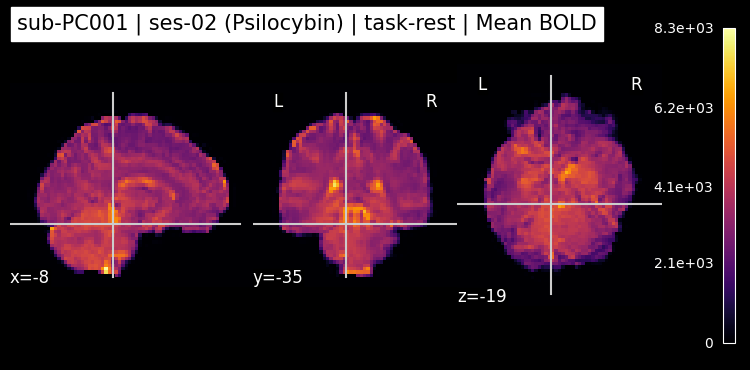

In [ ]:
!pip install -q nilearn awscli

import os
import glob
import subprocess
from nilearn import image, plotting

local_dir = "/content/data/sub-PC001/ses-02/func"
os.makedirs(local_dir, exist_ok=True)

s3_dir = "s3://openneuro.org/ds006110/derivatives/fmriprep-22.0.2/sub-PC001/ses-02/func/"
download_cmd = (
    f"aws s3 cp {s3_dir} {local_dir} --recursive "
    f"--exclude '*' --include '*task-rest*space-MNI152NLin2009cAsym_desc-preproc_bold.nii.gz' "
    f"--no-sign-request"
)
subprocess.run(download_cmd, shell=True, check=True)

# 3. Lokalizacja pobranego pliku 4D NIfTI
bold_files = glob.glob(f"{local_dir}/*task-rest*desc-preproc_bold.nii.gz")
if not bold_files:
    raise FileNotFoundError("Nie znaleziono pliku BOLD. Upewnij się, że pobieranie zakończyło się poprawnie.")

bold_path = bold_files[0]
print(f"Pobrano plik BOLD: {os.path.basename(bold_path)}")

# 4. Obliczenie średniego sygnału w czasie (agregacja wymiaru 4D do 3D)
mean_bold_img = image.mean_img(bold_path)

# 5. Wyświetlenie przekrojów ortogonalnych mózgu
plotting.plot_epi(
    mean_bold_img,
    title="sub-PC001 | ses-02 (Psilocybin) | task-rest | Mean BOLD",
    display_mode="ortho",
    draw_cross=True,
    colorbar=True,
    cmap="inferno"
)
plotting.show()